# v4 — Disagreement & error analysis (HTRU2)

**Goal.** Profile *who* each model gets wrong, not just how many. Partition the identical test set (SEED=42) by RF-vs-CNN correctness at 0.5, then characterise the 56-vs-21 discordant cases and the jointly-missed pulsars by feature — the SPINN-style low-scorer inspection. Decisions use RF raw probs and CNN T-scaled probs (T refit here, val only; must recover 0.718).


In [1]:
SEED = 42
import random
import numpy as np, pandas as pd
random.seed(SEED); np.random.seed(SEED)
import torch, torch.nn as nn
torch.manual_seed(SEED); torch.set_num_threads(4)
from pathlib import Path
import urllib.request, zipfile, io
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
DATA = Path("data") / "HTRU_2.csv"
if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
        "https://archive.ics.uci.edu/static/public/372/htru2.zip", timeout=120).read()))
    DATA.write_bytes(z.read("HTRU_2.csv"))
COLS = ["profile_mean","profile_stdev","profile_kurtosis","profile_skewness",
        "dm_mean","dm_stdev","dm_kurtosis","dm_skewness","target"]
df = pd.read_csv(DATA, header=None, names=COLS)
feats = COLS[:8]
X, y = df[feats].values, df["target"].values
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
sc = StandardScaler().fit(X_tr)
Z_tr, Z_va, Z_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)
rf = RandomForestClassifier(n_estimators=400, max_depth=20, min_samples_leaf=2,
    class_weight="balanced_subsample", random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
class CNN1d(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(1,16,2,padding=1), nn.ReLU())
        with torch.no_grad():
            self.fc = nn.Linear(self.conv(torch.zeros(1,1,8)).numel(), 2)
    def forward(self, x): return self.fc(self.conv(x).flatten(1))
cnn = CNN1d()
cnn.load_state_dict(torch.load("cnn_best.pt", weights_only=True)["state"]); cnn.eval()
def logits(Z):
    with torch.no_grad():
        return cnn(torch.tensor(Z, dtype=torch.float32).unsqueeze(1)).numpy()
z_va, z_te = logits(Z_va), logits(Z_te)
zv = torch.tensor(z_va); yv = torch.tensor(y_va)
logT = torch.zeros(1, requires_grad=True)
opt = torch.optim.LBFGS([logT], max_iter=100)
def _closure():
    opt.zero_grad()
    loss = nn.CrossEntropyLoss()(zv / logT.exp(), yv)
    loss.backward()
    return loss
opt.step(_closure)
T = float(logT.exp().detach())
p_rf = rf.predict_proba(X_te)[:,1]
p_cnn = torch.softmax(torch.tensor(z_te)/T, 1)[:,1].numpy()
print(f"T={T:.3f} (v3: 0.718) | test n={len(y_te)}")

T=0.718 (v3: 0.718) | test n=3580


## 1. Correctness partition (0.5 threshold)

Four groups: both-right, RF-only-right (CNN's unique errors), CNN-only-right (RF's unique errors), both-wrong (survey failures — a missed pulsar here is missed by *every* model in the dossier). Pulsar vs noise split inside each group tells us whether errors cost discoveries (FN) or telescope time (FP).


In [2]:
yr, yc = (p_rf>=0.5).astype(int), (p_cnn>=0.5).astype(int)
groups = {
  "both-right":     (yr==y_te)&(yc==y_te),
  "RF-only-right":  (yr==y_te)&(yc!=y_te),
  "CNN-only-right": (yr!=y_te)&(yc==y_te),
  "both-wrong":     (yr!=y_te)&(yc!=y_te),
}
print(f"{'group':<15}{'n':<6}{'pulsars':<9}{'noise':<7}fn-rate* fp-rate*")
for g, m in groups.items():
    pos, neg = int((y_te[m]==1).sum()), int((y_te[m]==0).sum())
    print(f"{g:<15}{m.sum():<6}{pos:<9}{neg:<7}{(pos/max((y_te==1).sum(),1)):.3f}   {(neg/max((y_te==0).sum(),1)):.3f}")
print("* group share of all test pulsars / all test noise")
bm = groups["both-wrong"]
print(f"\nboth-wrong pulsars (missed by all): {(y_te[bm]==1).sum()} of {(y_te==1).sum()} test pulsars")

group          n     pulsars  noise  fn-rate* fp-rate*
both-right     3452  283      3169   0.863   0.974
RF-only-right  56    0        56     0.000   0.017
CNN-only-right 21    21       0      0.064   0.000
both-wrong     51    24       27     0.073   0.008
* group share of all test pulsars / all test noise

both-wrong pulsars (missed by all): 24 of 328 test pulsars


## 2. Feature profiles — what marks each error group?

Group means in standardised units vs the test population. A group shifted toward the *opposite* class's typical profile on a feature is being fooled through that feature — the astrophysical read (pulse shape vs DM confirmation) goes here.


group means (standardised) vs population:
                profile_mean  profile_stdev  profile_kurtosis  profile_skewness  dm_mean  dm_stdev  dm_kurtosis  dm_skewness
both-right              0.03           0.01             -0.01              0.00    -0.02     -0.05         0.04         0.03
RF-only-right          -0.51           0.20              0.28             -0.13     0.21      0.63        -0.47        -0.42
CNN-only-right         -0.46           0.28              0.34             -0.10     0.74      1.28        -0.87        -0.62
both-wrong             -0.63          -0.12              0.41              0.04     0.97      1.21        -0.78        -0.45


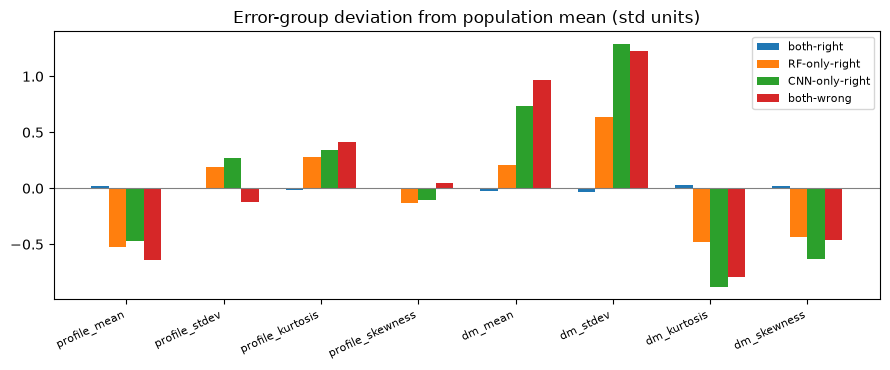

In [3]:
import matplotlib.pyplot as plt
te = pd.DataFrame(Z_te, columns=feats); te["y"] = y_te
prof = pd.DataFrame({g: te[m][feats].mean() for g, m in groups.items()}).T
pop = te[feats].mean()
print("group means (standardised) vs population:")
print((prof).round(2).to_string())
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(feats))
for j, g in enumerate(prof.index):
    ax.bar(x + (j-1.5)*0.18, prof.loc[g].values - pop.values, 0.18, label=g)
ax.set_xticks(x); ax.set_xticklabels(feats, rotation=25, ha="right", fontsize=8)
ax.axhline(0, color="gray", lw=0.8); ax.set_title("Error-group deviation from population mean (std units)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("docs/assets/error_profile.png", bbox_inches="tight"); plt.show()

## 3. Missed pulsars — score distributions (the survey-critical view)

False negatives are the expensive error (a lost discovery). For every test pulsar, compare the two models' scores: which model's misses are near-threshold (recoverable by moving T) vs confidently wrong (structurally missed)?


test pulsars=328 | RF misses=45 CNN misses=24 | both miss=24
missed-pulsar median score: RF=0.100 CNN=0.091


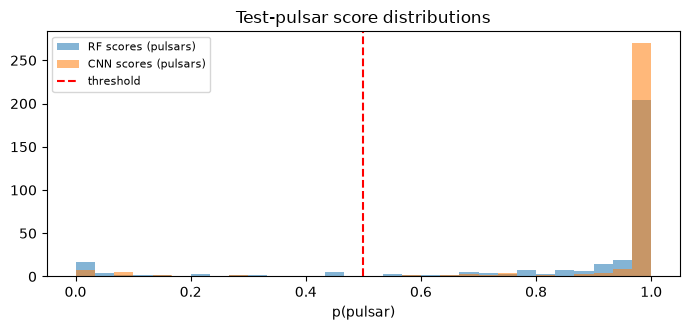


both-missed vs both-found pulsar means (std units):
                  both-missed  both-found
profile_mean            -0.15       -2.46
profile_stdev           -0.19       -1.36
profile_kurtosis        -0.06        2.92
profile_skewness        -0.15        2.64
dm_mean                 -0.22        1.47
dm_stdev                -0.03        1.69
dm_kurtosis              0.12       -1.36
dm_skewness              0.12       -0.90


In [4]:
pos = y_te==1
fn_rf, fn_cnn = pos & (yr==0), pos & (yc==0)
print(f"test pulsars={pos.sum()} | RF misses={fn_rf.sum()} CNN misses={fn_cnn.sum()} | both miss={(fn_rf&fn_cnn).sum()}")
print(f"missed-pulsar median score: RF={np.median(p_rf[fn_rf]):.3f} CNN={np.median(p_cnn[fn_cnn]):.3f}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(p_rf[pos], bins=30, alpha=0.55, label="RF scores (pulsars)")
ax.hist(p_cnn[pos], bins=30, alpha=0.55, label="CNN scores (pulsars)")
ax.axvline(0.5, color="red", ls="--", label="threshold")
ax.set_title("Test-pulsar score distributions"); ax.set_xlabel("p(pulsar)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("docs/assets/missed_scores.png", bbox_inches="tight"); plt.show()
both_fn = te[fn_rf & fn_cnn][feats].mean()
hit = te[pos & (yr==1) & (yc==1)][feats].mean()
print("\nboth-missed vs both-found pulsar means (std units):")
print(pd.DataFrame({"both-missed": both_fn, "both-found": hit}).round(2).to_string())

## 4. Findings (measured, SEED=42)

- Stark asymmetry: RF-only-right (56) is **all noise** — CNN's unique errors are pure false alarms, never lost discoveries. CNN-only-right (21) is **all pulsars** — RF's unique errors are pure missed discoveries. Every CNN pulsar-miss is also an RF miss (24/24); CNN recovers 21 pulsars RF loses and loses none RF keeps.
- 24 of 328 test pulsars (7.3%) are missed by *both* — the survey-critical failures. Both-missed pulsars sit near the population mean on all 8 features while found pulsars are extreme (profile kurtosis +2.9σ, skewness +2.6σ): weak, atypical profiles. CNN-recovered pulsars show elevated DM features (dm_stdev +1.3σ) — the DM-confirmation pathway.
- Missed-pulsar median scores are 0.09–0.10 (both models): confidently wrong, not near-threshold. Moving T cannot recover them — new information (features/data), not new thresholds, is the way forward.

- Direct input to paper §4 (error analysis) — numbers above are the evidence.
